# 04 - Ablation and Comparative Analysis

**Purpose.** Assemble research tables and figures from saved results only (no retraining): Track A comparison, CNN-Transformer comparison, quantum vs classical controls, quantum ablations, feature-module and preprocessing ablations, patient-level CIs and paired tests. Missing or failed experiments are listed explicitly.

**Requires (inputs).** Outputs of notebooks 00-03 for the same MODE (attach them as inputs on Kaggle).

**Produces (outputs, under `/kaggle/working/rsna_ich_artifacts/<MODE>/`).** `analysis/final_*.csv`, `analysis/final_*.md`, `analysis/figures/*.png`, `analysis/experiment_status.csv`.

> Research software. Outputs are model predictions for a research study and **not** clinical diagnoses.
> Results in this notebook are only valid for the MODE they were produced in (`smoke` results check correctness and say nothing about performance).

In [1]:
# ==== Setup: locate the project code and make `src` importable ====================================
# Works on Kaggle (project code attached as a Dataset, possibly nested after zip extraction) and locally.
import os, sys, importlib
from pathlib import Path

def find_project_root(max_depth: int = 5) -> Path:
    def ok(p: Path) -> bool:
        return (p / "src" / "__init__.py").is_file() and (p / "configs" / "data_config.yaml").is_file()
    cands = []
    if os.environ.get("RSNA_ICH_PROJECT_ROOT"):
        cands.append(Path(os.environ["RSNA_ICH_PROJECT_ROOT"]))
    cands += [Path.cwd(), Path.cwd().parent, Path("/kaggle/working/RSNA_ICH_Research")]
    for c in cands:
        if ok(c):
            return c.resolve()
    for base in (Path("/kaggle/input"), Path("/kaggle/working")):
        if not base.exists():
            continue
        stack = [(base, 0)]
        while stack:
            d, depth = stack.pop()
            if ok(d):
                return d.resolve()
            if depth < max_depth:
                try:
                    stack += [(p, depth + 1) for p in d.iterdir() if p.is_dir() and not p.name.startswith("stage_2_")]
                except OSError:
                    pass
    raise FileNotFoundError(
        "Project code not found. On Kaggle: 'Add Input' -> the dataset containing RSNA_ICH_Research "
        "(with src/ and configs/). Locally: run the notebook from RSNA_ICH_Research/notebooks or set "
        "the RSNA_ICH_PROJECT_ROOT environment variable.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in ["src", "src.utils.context", "src.data", "src.models", "src.quantum", "src.training", "src.evaluation"]:
    importlib.import_module(_m)  # fails loudly here if a dependency is missing
import src
print(f"Project root: {PROJECT_ROOT}  |  src version {src.__version__}")

Project root: /kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research  |  src version 1.0.0


In [2]:
# ==== Configuration ================================================================================
# MODE: "smoke" (correctness check, minutes) | "pilot" (representative subset) | "full" (largest feasible).
MODE = "pilot"
# Optional per-config overrides without editing YAML, e.g. {"transformer": {"train": {"epochs": 2}}}
OVERRIDES = {}
import json
if os.environ.get("RSNA_ICH_OVERRIDES_JSON"):          # test hook used by tools/run_notebooks_synthetic.py
    OVERRIDES = json.loads(os.environ["RSNA_ICH_OVERRIDES_JSON"])
MODE = os.environ.get("RSNA_ICH_MODE", MODE)

from src.utils.context import ProjectContext
ctx = ProjectContext(PROJECT_ROOT, MODE, OVERRIDES)
print(ctx.describe())
print("Installed packages:", ctx.runtime.packages)
ctx.save_run_info("04_analysis")

ProjectContext(mode=pilot, root=/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research, output=/kaggle/working/rsna_ich_artifacts/pilot)
  GPU: Tesla T4 (15.6 GB), Tesla T4 (15.6 GB) | CUDA=True bf16=False | CPUs=4 | RAM avail=31.79 GB | free disk (/kaggle/working/rsna_ich_artifacts)=20.94 GB
Installed packages: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/run_info/04_analysis.json')

In [3]:
# ==== Unpack experiments from zipped notebook outputs (Kaggle zips outputs with many files) ====
import glob, zipfile, shutil
key = f"{MODE}/experiments/"
dst_root = ctx.output_root / "experiments"
zips = [z for pat in ["/kaggle/input/*/_output_.zip", "/kaggle/input/*/*/_output_.zip",
                      "/kaggle/input/*/*/*/_output_.zip", "/kaggle/input/*/*/*/*/_output_.zip"]
        for z in glob.glob(pat)]
print("Zipped inputs:", zips)
n = 0
for z in zips:
    with zipfile.ZipFile(z) as zf:
        for name in zf.namelist():
            if key not in name or name.endswith("/") or name.endswith("last.pt"):
                continue
            rel = name.split(key, 1)[1]
            if not rel.startswith(("A_", "B_", "H_")):
                continue
            out = dst_root / rel
            if out.exists():
                continue
            out.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(name) as src, open(out, "wb") as f:
                shutil.copyfileobj(src, f)
            n += 1
print(f"Extracted {n} files")
print(sorted(p.name for p in dst_root.iterdir() if p.is_dir()))

Zipped inputs: ['/kaggle/input/notebooks/mehulkhannaa/01-classical-transformer-benchmark/_output_.zip']
Extracted 62 files
['A_deit_small', 'A_maxvit_tiny', 'A_swin_tiny', 'H_maxvit_tiny_brain3']


In [4]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src import LABELS
from src.utils.io import atomic_write_json, atomic_save_dataframe, read_json, dataframe_to_markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

In [5]:
manifest, man_info = ctx.manifest()
an_dir, fig_dir = ctx.dir("analysis"), ctx.dir("analysis", "figures")
res = ctx.results()
print(f"Found {len(res)} experiment result files across working dir and attached inputs.")
N_BOOT = {"smoke": 50, "pilot": 300, "full": 1000}[MODE]

Found 37 experiment result files across working dir and attached inputs.


## 1. Planned vs executed experiments (nothing is filled in for missing runs)

In [6]:
tc, hc, qc = ctx.cfg["transformer"], ctx.cfg["hybrid"], ctx.cfg["quantum"]
planned = [(f"A_{m['name']}", "A: standalone Transformer") for m in tc["models"]]
planned += [(f"A_{m['name']}", "A: optional Transformer") for m in tc.get("optional_models", []) if m["name"] in tc.get("run_optional", [])]
planned += [("B_cnn_transformer_hybrid", "G: CNN-Transformer hybrid"), (f"B_cnn_reference_{hc['cnn_reference']['name']}", "CNN reference")]
planned += [(f"B_hybrid_fusion_{f}", "feature-module ablation") for f in hc.get("fusion_ablation", [])]
grid = list(qc["primary"]) + (list(qc["ablations"]) if qc["run_ablations"] else [])
planned += [(f"C_{s['id']}_s{seed}", "C/B/D/E/F: heads on frozen features") for s in grid for seed in qc["seeds"]]
status = {r["experiment_id"]: r["status"] for _, r in res.iterrows()} if len(res) else {}
h_runs = [e for e in status if e.startswith("H_")]
planned += [(e, "H: single-window input") for e in h_runs] or [("H_<best>_brain3", "H: single-window input")]
st = pd.DataFrame([{"experiment": e, "role": role, "status": status.get(e, "NOT RUN / NOT FOUND")} for e, role in planned])
display(st["status"].value_counts().to_frame("count")); display(st)
atomic_save_dataframe(st, an_dir / "experiment_status.csv")

,count
status,
succeeded,37


,experiment,role,status
0,A_deit_small,A: standalone Transformer,succeeded
1,A_swin_tiny,A: standalone Transformer,succeeded
2,A_maxvit_tiny,A: standalone Transformer,succeeded
3,B_cnn_transformer_hybrid,G: CNN-Transformer hybrid,succeeded
4,B_cnn_reference_efficientnet_b0,CNN reference,succeeded
5,B_hybrid_fusion_gap_only,feature-module ablation,succeeded
6,C_linear_probe_s0,C/B/D/E/F: heads on frozen features,succeeded
7,C_linear_probe_s1,C/B/D/E/F: heads on frozen features,succeeded
8,C_linear_probe_s2,C/B/D/E/F: heads on frozen features,succeeded
9,C_bottleneck_identity_s0,C/B/D/E/F: heads on frozen features,succeeded


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/analysis/experiment_status.csv')

## 2. Image-model comparison (Tracks A, B, G, H) with patient-level bootstrap CIs on the held-out test set

,model,weights,val_macro_auc,estimate,ci_low,ci_high,test_macro_ap,auc_epidural,auc_intraparenchymal,auc_intraventricular,auc_subarachnoid,auc_subdural,auc_any,test_macro_f1,test_hamming,test_brier
1,A_maxvit_tiny,pretrained,0.9577,0.9221,0.8700,0.9571,0.5980,0.7825,0.9697,0.9703,0.9346,0.9267,0.9489,0.4623,0.0974,0.0438
3,H_maxvit_tiny_brain3,pretrained,0.9560,0.9209,0.8784,0.9552,0.5953,0.7927,0.9714,0.9672,0.9251,0.9236,0.9453,0.4450,0.1011,0.0417
2,A_swin_tiny,pretrained,0.9540,0.9132,0.8747,0.9548,0.5994,0.7376,0.9649,0.9709,0.9289,0.9314,0.9455,0.4520,0.1039,0.0389
0,A_deit_small,pretrained,0.9479,0.9114,0.8723,0.9474,0.5850,0.7571,0.9587,0.9698,0.9200,0.9208,0.9418,0.4258,0.1126,0.0425
5,B_cnn_transformer_hybrid,pretrained,0.9398,0.9123,0.8623,0.9456,0.5551,0.7877,0.9536,0.9601,0.9147,0.9185,0.9390,0.3963,0.1364,0.0382
6,B_hybrid_fusion_gap_only,pretrained,0.9374,0.9009,0.8514,0.9375,0.4934,0.7699,0.9434,0.9567,0.9011,0.9046,0.9298,0.3703,0.1465,0.0458
4,B_cnn_reference_efficientnet_b0,pretrained,0.9368,0.9092,0.8812,0.9421,0.5401,0.7793,0.9561,0.9570,0.9091,0.9173,0.9365,0.3890,0.1502,0.0407


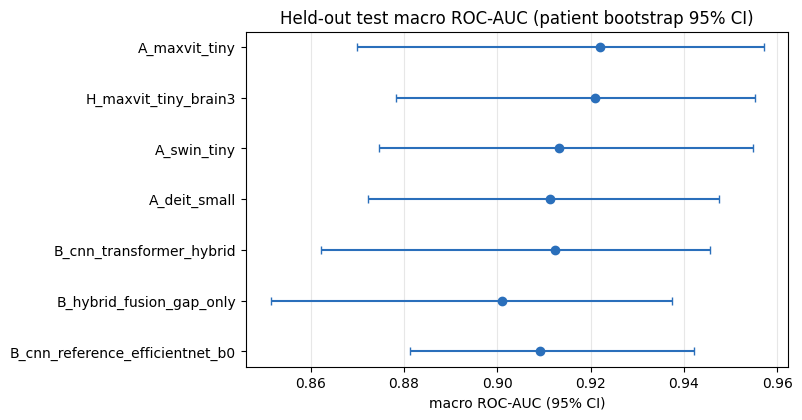

In [7]:
from src.evaluation.predictions import load_predictions, arrays, align
from src.evaluation.statistics import bootstrap_table, paired_bootstrap, holm
from src.evaluation.visualization import plot_forest
img = res[res["experiment_id"].str.match(r"^(A|B|H)_") & (res["status"] == "succeeded")] if len(res) else res
rows, preds = [], {}
for _, r in img.iterrows():
    d = Path(r["_dir"])
    df, _ = load_predictions(d / "predictions_test.parquet", man_info["manifest_hash"])
    preds[r["experiment_id"]] = df
    p, t = arrays(df)
    ci = bootstrap_table(t, p, df["group_id"].to_numpy(), ["macro_auc", "macro_ap", "auc:any"], n_boot=N_BOOT, seed=0).set_index("metric")
    per = pd.read_csv(d / "metrics_test_per_label.csv").set_index("label")["roc_auc"]
    rows.append({"model": r["experiment_id"], "weights": r["build"]["status"], "val_macro_auc": r["val_metrics"]["macro_roc_auc"],
                 "estimate": ci.loc["macro_auc", "estimate"], "ci_low": ci.loc["macro_auc", "ci_low"], "ci_high": ci.loc["macro_auc", "ci_high"],
                 "test_macro_ap": ci.loc["macro_ap", "estimate"], **{f"auc_{l}": per[l] for l in LABELS},
                 "test_macro_f1": r["test_metrics"]["macro_f1"], "test_hamming": r["test_metrics"]["hamming_loss"],
                 "test_brier": r["test_metrics"]["mean_brier"]})
image_table = pd.DataFrame(rows).sort_values("val_macro_auc", ascending=False) if rows else pd.DataFrame()
display(image_table.round(4))
if len(image_table):
    atomic_save_dataframe(image_table, an_dir / "final_image_models.csv")
    (an_dir / "final_image_models.md").write_text(dataframe_to_markdown(image_table), encoding="utf-8")
    plot_forest(image_table, "model", fig_dir / "forest_image_models.png", "Held-out test macro ROC-AUC (patient bootstrap 95% CI)"); plt.show()

## 3. Paired comparisons on identical test images (patient-cluster bootstrap, Holm-adjusted)
Reference = the best model by **validation** macro AUC.

In [8]:
recs = []
if len(image_table) >= 2:
    ref = image_table.iloc[0]["model"]
    for o in image_table["model"].iloc[1:]:
        ids, al = align({"a": preds[ref], "b": preds[o]})
        pa, t = arrays(al["a"]); pb, _ = arrays(al["b"])
        recs.append({"comparison": f"{ref} - {o}", "n_images": len(ids),
                     **paired_bootstrap(t, pa, pb, al["a"]["group_id"].to_numpy(), "macro_auc", N_BOOT, 0)})
paired = pd.DataFrame(recs)
if len(paired):
    paired["p_holm"] = holm(paired["p_value"])
    atomic_save_dataframe(paired, an_dir / "final_paired_image_models.csv")
display(paired.round(4))

,comparison,n_images,metric,difference,ci_low,ci_high,p_value,n_valid,method,p_holm
0,A_maxvit_tiny - H_maxvit_tiny_brain3,9552,macro_auc,0.0012,-0.0102,0.0108,0.8200,300,paired patient-cluster bootstrap,1.00
1,A_maxvit_tiny - A_swin_tiny,9552,macro_auc,0.0089,-0.0072,0.0312,0.4400,300,paired patient-cluster bootstrap,1.00
2,A_maxvit_tiny - A_deit_small,9552,macro_auc,0.0108,-0.0050,0.0243,0.1600,300,paired patient-cluster bootstrap,0.64
3,A_maxvit_tiny - B_cnn_transformer_hybrid,9552,macro_auc,0.0098,0.0017,0.0290,0.0200,300,paired patient-cluster bootstrap,0.10
4,A_maxvit_tiny - B_hybrid_fusion_gap_only,9552,macro_auc,0.0212,0.0122,0.0329,0.0033,300,paired patient-cluster bootstrap,0.02
5,A_maxvit_tiny - B_cnn_reference_efficientnet_b0,9552,macro_auc,0.0129,-0.0178,0.0375,0.3467,300,paired patient-cluster bootstrap,1.00


## 4. Quantum vs classical controls and quantum ablations (from notebook 03 runs)

,head,test_n,test_mean,test_sd,test_ci_low,test_ci_high,val_mean,params,failed_runs
0,bottleneck_identity,3,0.9135,0.0080,0.8935,0.9335,0.9525,2242,0
1,bottleneck_mlp_k8,3,0.9104,0.0064,0.8945,0.9262,0.9501,4438,0
2,bottleneck_mlp,3,0.9130,0.0040,0.9030,0.9231,0.9497,2262,0
3,linear_probe,3,0.9148,0.0006,0.9132,0.9163,0.9580,3078,0
4,vqc_q2_l2_cyclic,3,0.8754,0.0260,0.8108,0.9399,0.9065,1192,0
5,vqc_q4_l1_cyclic,3,0.9076,0.0052,0.8948,0.9204,0.9477,2254,0
6,vqc_q4_l2_cyclic,3,0.9036,0.0045,0.8925,0.9147,0.9387,2266,0
7,vqc_q4_l2_noent,3,0.9079,0.0055,0.8942,0.9215,0.9459,2266,0
8,vqc_q4_l4_cyclic,3,0.9056,0.0056,0.8916,0.9196,0.9442,2290,0
9,vqc_q8_l2_cyclic,3,0.9042,0.0011,0.9015,0.9069,0.9403,4414,0


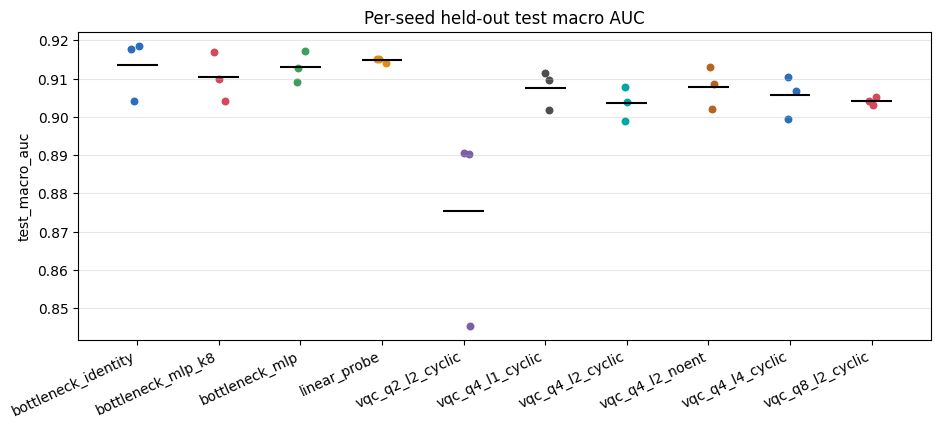

,ablation,a,b,n,mean_difference,t_stat,p_ttest,p_wilcoxon
0,C vs B (parameter-matched classical block),vqc_q4_l2_cyclic,bottleneck_mlp,3,-0.0094,-2.1624,0.1631,0.25
1,C vs bottleneck only,vqc_q4_l2_cyclic,bottleneck_identity,3,-0.0099,-1.4399,0.2866,0.50
2,C vs linear probe (A-features),vqc_q4_l2_cyclic,linear_probe,3,-0.0112,-4.9558,0.0384,0.25
3,D: entanglement vs none,vqc_q4_l2_cyclic,vqc_q4_l2_noent,3,-0.0043,-1.6928,0.2326,0.25
4,E: depth 4 vs 2,vqc_q4_l4_cyclic,vqc_q4_l2_cyclic,3,0.0020,0.8499,0.4849,0.75
5,E: depth 1 vs 2,vqc_q4_l1_cyclic,vqc_q4_l2_cyclic,3,0.0040,0.7355,0.5386,0.75
6,F: 8 qubits vs k=8 classical,vqc_q8_l2_cyclic,bottleneck_mlp_k8,3,-0.0061,-1.5142,0.2692,0.50
7,F: 2 vs 4 qubits,vqc_q2_l2_cyclic,vqc_q4_l2_cyclic,3,-0.0282,-2.2145,0.1572,0.25


In [9]:
from src.evaluation.statistics import seed_summary, paired_seed_test
c_res = res[res["experiment_id"].str.startswith("C_")] if len(res) else res
if len(c_res):
    c_res = c_res.assign(head=c_res["experiment_id"].str.replace(r"_s\d+$", "", regex=True).str[2:],
                         seed=c_res["experiment_id"].str.extract(r"_s(\d+)$")[0].astype(int))
    ok = c_res[c_res["status"] == "succeeded"].copy()
    ok["test_macro_auc"] = ok["test_metrics"].apply(lambda m: m["macro_roc_auc"])
    ok["val_macro_auc"] = ok["val_metrics"].apply(lambda m: m["macro_roc_auc"])
    ok["params"] = ok["head_params"].apply(lambda m: m["total"])
    q_table = pd.DataFrame([{"head": h, **{f"test_{k}": v for k, v in seed_summary(g["test_macro_auc"]).items()},
                             "val_mean": g["val_macro_auc"].mean(), "params": g["params"].iloc[0],
                             "failed_runs": int((c_res[(c_res["head"] == h)]["status"] != "succeeded").sum())}
                            for h, g in ok.groupby("head", sort=False)])
    display(q_table.round(4)); atomic_save_dataframe(q_table, an_dir / "final_quantum_heads.csv")
    (an_dir / "final_quantum_heads.md").write_text(dataframe_to_markdown(q_table), encoding="utf-8")
    from src.evaluation.visualization import plot_seed_comparison
    plot_seed_comparison(ok, "head", "test_macro_auc", fig_dir / "quantum_heads_by_seed.png", "Per-seed held-out test macro AUC"); plt.show()
    tests = []
    for a, b, label in [("vqc_q4_l2_cyclic", "bottleneck_mlp", "C vs B (parameter-matched classical block)"),
                        ("vqc_q4_l2_cyclic", "bottleneck_identity", "C vs bottleneck only"),
                        ("vqc_q4_l2_cyclic", "linear_probe", "C vs linear probe (A-features)"),
                        ("vqc_q4_l2_cyclic", "vqc_q4_l2_noent", "D: entanglement vs none"),
                        ("vqc_q4_l4_cyclic", "vqc_q4_l2_cyclic", "E: depth 4 vs 2"), ("vqc_q4_l1_cyclic", "vqc_q4_l2_cyclic", "E: depth 1 vs 2"),
                        ("vqc_q8_l2_cyclic", "bottleneck_mlp_k8", "F: 8 qubits vs k=8 classical"), ("vqc_q2_l2_cyclic", "vqc_q4_l2_cyclic", "F: 2 vs 4 qubits")]:
        A, B = ok[ok["head"] == a], ok[ok["head"] == b]
        if len(A) and len(B):
            m = A.merge(B, on="seed", suffixes=("_a", "_b"))
            tests.append({"ablation": label, "a": a, "b": b, **paired_seed_test(m["test_macro_auc_a"], m["test_macro_auc_b"])})
        else:
            tests.append({"ablation": label, "a": a, "b": b, "n": 0, "note": "not run"})
    abl = pd.DataFrame(tests); display(abl.round(4)); atomic_save_dataframe(abl, an_dir / "final_quantum_ablations.csv")
else:
    print("No Track-C results found (attach notebook 03 output).")

## 5. Statistical method (for the report)
* **CIs:** patient-cluster percentile bootstrap (patients resampled with replacement, all their slices kept). Slices are not treated as independent.
* **Paired model comparisons:** paired patient-cluster bootstrap of the macro-AUC difference on identical test images; two-sided bootstrap p-value; Holm correction across comparisons.
* **Seed variability (Track C):** mean, SD and t-interval across training seeds; paired t-test / Wilcoxon across seeds (small n - interpret with caution).
* **Thresholds** were selected on validation (Youden J per label) and frozen before test evaluation.
* **Assumptions:** patients are independent; percentile intervals may be anti-conservative when few patients are positive for a label (epidural).